**PART 1 : Installation**

```
# This is formatted as code
```



In [ ]:
%pip install -q fastapi uvicorn requests


In [ ]:
import tensorflow as tf
import numpy as np
import fastapi
import requests

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Environment Ready!")

TensorFlow Version: 2.21.0
NumPy Version: 2.4.6
Environment Ready!


**Part 2 – Build and train the CNN model**

In [ ]:
# STEP 2: Load MNIST dataset

(x_train, y_train), (x_test, y_test) = \
    tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [ ]:
# Normalize image values

x_train = x_train.reshape(-1, 28, 28, 1).astype('float32') / 255.0

x_test = x_test.reshape(-1, 28, 28, 1).astype('float32') / 255.0

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)


Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)


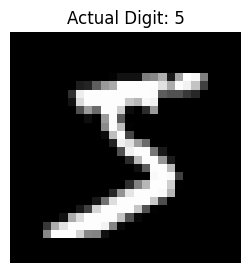

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(3,3))

plt.imshow(x_train[0].squeeze(), cmap='gray')

plt.title(f"Actual Digit: {y_train[0]}")

plt.axis('off')

plt.show()


In [ ]:

# STEP 3: Build CNN Model

model = tf.keras.Sequential([

    tf.keras.layers.Conv2D(
        8,
        kernel_size=3,
        activation='relu',
        padding='same',
        input_shape=(28, 28, 1)
    ),

    tf.keras.layers.MaxPooling2D(pool_size=2),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(32, activation='relu'),

    tf.keras.layers.Dense(10, activation='softmax')

], name='mnist_cnn')

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        50,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,618 (197.73 KB)

 Trainable params: 50,618 (197.73 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# STEP 4: Compile the CNN

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)


Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.9093 - loss: 0.3193 - val_accuracy: 0.9708 - val_loss: 0.1092
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 23ms/step - accuracy: 0.9665 - loss: 0.1149 - val_accuracy: 0.9758 - val_loss: 0.0847
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9751 - loss: 0.0832 - val_accuracy: 0.9785 - val_loss: 0.0796
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.9799 - loss: 0.0667 - val_accuracy: 0.9787 - val_loss: 0.0752
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 23ms/step - accuracy: 0.9838 - loss: 0.0549 - val_accuracy: 0.9823 - val_loss: 0.0628


In [ ]:
# STEP 5: Evaluate model

loss, accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Test Loss:", loss)

print("Test Accuracy:", accuracy)

print("Accuracy Percentage:", accuracy * 100)


Test Loss: 0.05953910946846008
Test Accuracy: 0.9804999828338623
Accuracy Percentage: 98.04999828338623


In [ ]:
# STEP 6: Save trained model

model.save("mnist_model.keras")

# Save one test image

np.save("test_sample.npy", x_test[:1])

print("Model saved successfully!")
print("Test sample saved successfully!")

Model saved successfully!
Test sample saved successfully!


**Part 3 – Convert CNN into TensorFlow Lit**e

In [ ]:

# STEP 7: TensorFlow Lite conversion

import os

# Load trained model
model = tf.keras.models.load_model("mnist_model.keras")

# Create TFLite converter
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Enable dynamic range quantization
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Convert model
tflite_model = converter.convert()

# Save model
with open("model.tflite", "wb") as f:
    f.write(tflite_model)

# Compare model sizes
keras_size = os.path.getsize("mnist_model.keras") / 1024

tflite_size = os.path.getsize("model.tflite") / 1024

print("Keras Model Size:", round(keras_size, 2), "KB")

print("TFLite Model Size:", round(tflite_size, 2), "KB")

print("Compression Ratio:", round(keras_size/tflite_size, 2))

print("TFLite conversion completed!")


Saved artifact at '/tmp/tmppicyd53z'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  132454107096144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132454107095376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132454121613520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132454114690448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132454106047568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132454106045456: TensorSpec(shape=(), dtype=tf.resource, name=None)
Keras Model Size: 622.59 KB
TFLite Model Size: 54.65 KB
Compression Ratio: 11.39
TFLite conversion completed!


In [ ]:

# STEP 8: Load TFLite model

interpreter = tf.lite.Interpreter(
    model_path="model.tflite"
)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()

output_details = interpreter.get_output_details()

print("Input Shape:", input_details[0]['shape'])

print("Output Shape:", output_details[0]['shape'])


Input Shape: [ 1 28 28  1]
Output Shape: [ 1 10]


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:

# STEP 9: Edge inference

import time

x = np.load("test_sample.npy")

# Warm-up
interpreter.set_tensor(
    input_details[0]['index'], x
)

interpreter.invoke()

# Run 100 inferences
N = 100

times = []

for i in range(N):

    start = time.perf_counter()

    interpreter.set_tensor(
        input_details[0]['index'], x
    )

    interpreter.invoke()

    end = time.perf_counter()

    times.append((end-start)*1000)

times = np.array(times)

# Prediction
output = interpreter.get_tensor(
    output_details[0]['index']
)

prediction = np.argmax(output)

confidence = np.max(output)

print("Predicted Digit:", prediction)

print("Confidence:", confidence)

print("Mean Latency:", times.mean(), "ms")

print("Median Latency:", np.median(times), "ms")

print("P95 Latency:", np.percentile(times, 95), "ms")

print("Throughput:", 1000/times.mean(), "inferences/sec")


Predicted Digit: 7
Confidence: 0.99985087
Mean Latency: 0.07945883000047615 ms
Median Latency: 0.02750449993982329 ms
P95 Latency: 0.06718554989220137 ms
Throughput: 12585.13371004843 inferences/sec


In [ ]:

# STEP 10: Create FastAPI server

from fastapi import FastAPI
from pydantic import BaseModel
import numpy as np
import time

app = FastAPI(title="Edge AI Cloud Simulation")

# Load model inside the server

cloud_interpreter = tf.lite.Interpreter(
    model_path="model.tflite"
)

cloud_interpreter.allocate_tensors()

cloud_input = cloud_interpreter.get_input_details()[0]

cloud_output = cloud_interpreter.get_output_details()[0]


# Request structure

class ImageRequest(BaseModel):
    data: list


# Health check API

@app.get("/")
def health():

    return {"status": "healthy"}


# Prediction API

@app.post("/infer")
def infer(req: ImageRequest):

    x = np.array(
        req.data,
        dtype=np.float32
    ).reshape(1, 28, 28, 1)

    start = time.perf_counter()

    cloud_interpreter.set_tensor(
        cloud_input['index'], x
    )

    cloud_interpreter.invoke()

    server_time = (
        time.perf_counter() - start
    ) * 1000

    result = cloud_interpreter.get_tensor(
        cloud_output['index']
    )

    prediction = int(np.argmax(result))

    confidence = float(np.max(result))

    return {
        "prediction": prediction,
        "confidence": round(confidence, 4),
        "server_latency_ms": round(server_time, 3),
        "payload_bytes": len(req.data) * 4
    }

print("FastAPI application created!")


FastAPI application created!


In [ ]:

# STEP 11: Start server in background

import threading
import uvicorn
import requests
import time

config = uvicorn.Config(
    app,
    host="127.0.0.1",
    port=8000,
    log_level="error"
)

server = uvicorn.Server(config)

server_thread = threading.Thread(
    target=server.run,
    daemon=True
)

server_thread.start()

# Wait until server becomes available

for i in range(30):

    try:
        response = requests.get(
            "http://127.0.0.1:8000/",
            timeout=2
        )

        if response.status_code == 200:
            break

    except requests.exceptions.RequestException:
        time.sleep(1)

print(response.json())


{'status': 'healthy'}


In [ ]:

# STEP 12: Cloud client

import json

x = np.load("test_sample.npy")

# Convert image into JSON payload

payload = {
    "data": x.flatten().tolist()
}

# Calculate transmitted payload size

payload_bytes = len(
    json.dumps(payload).encode("utf-8")
)

print("Payload Size:", payload_bytes, "bytes")

# Send image to server

response = requests.post(
    "http://127.0.0.1:8000/infer",
    json=payload
)

print("Server Response:")

print(response.json())


Payload Size: 5687 bytes
Server Response:
{'prediction': 7, 'confidence': 0.9999, 'server_latency_ms': 0.184, 'payload_bytes': 3136}


In [ ]:

# STEP 13: Cloud latency benchmark

N = 100

rtt_times = []

server_times = []

# Warm-up
requests.post(
    "http://127.0.0.1:8000/infer",
    json=payload
)

for i in range(N):

    start = time.perf_counter()

    response = requests.post(
        "http://127.0.0.1:8000/infer",
        json=payload
    )

    end = time.perf_counter()

    result = response.json()

    rtt_times.append(
        (end-start)*1000
    )

    server_times.append(
        result["server_latency_ms"]
    )

rtt_times = np.array(rtt_times)

server_times = np.array(server_times)

print("Cloud Server Mean:",
      server_times.mean(), "ms")

print("Cloud RTT Mean:",
      rtt_times.mean(), "ms")

print("Cloud RTT P95:",
      np.percentile(rtt_times, 95), "ms")

print("Network and HTTP Overhead:",
      rtt_times.mean()-server_times.mean(), "ms")

print("Payload Size:", payload_bytes, "bytes")


Cloud Server Mean: 0.12971000000000002 ms
Cloud RTT Mean: 5.298748920004073 ms
Cloud RTT P95: 6.233244450129405 ms
Network and HTTP Overhead: 5.1690389200040725 ms
Payload Size: 5687 bytes


In [ ]:

# STEP 14: Edge vs Cloud Comparison

edge_mean = times.mean()

edge_median = np.median(times)

edge_p95 = np.percentile(times, 95)

cloud_mean = rtt_times.mean()

cloud_median = np.median(rtt_times)

cloud_p95 = np.percentile(rtt_times, 95)

edge_prediction = int(prediction)

cloud_prediction = int(result["prediction"])

print("="*65)

print(f"{'METRIC':<25}{'EDGE':>18}{'CLOUD RTT':>18}")

print("="*65)

print(f"{'Mean Latency (ms)':<25}{edge_mean:>18.3f}{cloud_mean:>18.3f}")

print(f"{'Median Latency (ms)':<25}{edge_median:>18.3f}{cloud_median:>18.3f}")

print(f"{'P95 Latency (ms)':<25}{edge_p95:>18.3f}{cloud_p95:>18.3f}")

print(f"{'Throughput (inf/sec)':<25}{1000/edge_mean:>18.2f}{1000/cloud_mean:>18.2f}")

print(f"{'Data per request':<25}{'0 bytes':>18}{str(payload_bytes)+' B':>18}")

print(f"{'Network Required':<25}{'No':>18}{'Yes':>18}")

print(f"{'Prediction':<25}{edge_prediction:>18}{cloud_prediction:>18}")

print("="*65)

print("Edge Speedup:",
      round(cloud_mean/edge_mean, 2), "x")

print("Predictions Match:",
      edge_prediction == cloud_prediction)


METRIC                                 EDGE         CLOUD RTT
Mean Latency (ms)                     0.079             5.299
Median Latency (ms)                   0.028             5.161
P95 Latency (ms)                      0.067             6.233
Throughput (inf/sec)               12585.13            188.72
Data per request                    0 bytes            5687 B
Network Required                         No               Yes
Prediction                                7                 7
Edge Speedup: 66.69 x
Predictions Match: True


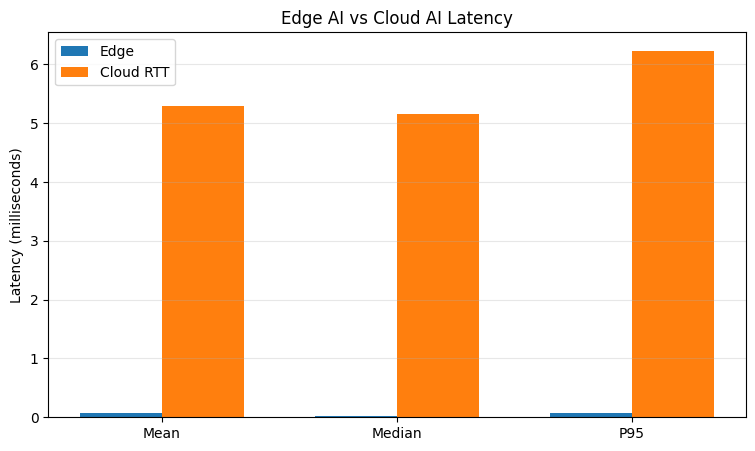

In [ ]:

import matplotlib.pyplot as plt

metrics = ["Mean", "Median", "P95"]

edge_values = [
    edge_mean,
    edge_median,
    edge_p95
]

cloud_values = [
    cloud_mean,
    cloud_median,
    cloud_p95
]

positions = np.arange(len(metrics))

width = 0.35

plt.figure(figsize=(9,5))

plt.bar(
    positions-width/2,
    edge_values,
    width,
    label="Edge"
)

plt.bar(
    positions+width/2,
    cloud_values,
    width,
    label="Cloud RTT"
)

plt.xticks(positions, metrics)

plt.ylabel("Latency (milliseconds)")

plt.title("Edge AI vs Cloud AI Latency")

plt.legend()

plt.grid(axis='y', alpha=0.3)

plt.show()


In [ ]:

from google.colab import files

files.download("mnist_model.keras")

files.download("model.tflite")

files.download("test_sample.npy")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>